# 10. Применение согласованных правил числового качества

## 1. Решение и область применения

Пользователь принял маскировку отдельных сомнительных полей четырех экстремумов
и обеих компонент 14 несогласованных температурных пар. Все посадки, исходные
сообщения и декодированные числа сохраняются. Изменения относятся только к
полям с суффиксом `_model` в отдельной числовой копии признаков.

Эта копия не является готовым набором для обучения: временная доступность,
пропуски, COR и остаточные замечания декодера требуют отдельных решений.
Исходные файлы `data/full/results/` не изменяются. Обучение не выполняется.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
decision=json.loads((R/'17_numeric_quality_protocol.json').read_text(encoding='utf8'))
application=json.loads((R/'18_numeric_mask_application.json').read_text(encoding='utf8'))
assert decision['status']=='accepted'
assert application['all_source_rows_present_once'] and application['raw_fields_unchanged']
assert application['source_files_unchanged'] and application['unmasked_model_values_unchanged']
assert application['rows_deleted']==0 and not application['training_executed']
assert application['input_sha256']==manifest['input_sha256']
display(pd.DataFrame([{key:value for key,value in application.items() if key!='files'}]))
registry=pd.read_csv(R/'17_numeric_quality_preview.csv')
readable_table(registry[['station','metar_utc','numeric_quality_reasons','proposed_mask_fields','linked_rows']])


,version,decision,applied_utc,input_sha256,registry_sha256,implementation_sha256,rows,go_arounds,all_source_rows_present_once,raw_fields_unchanged,source_files_unchanged,unmasked_model_values_unchanged,rows_deleted,training_executed,numeric_copy_only,matched_60min_flagged_rows,all_status_flagged_rows,masked_cells
0,numeric-quality-v1,accepted,2026-10-10T21:17:12.097151+00:00,1111c7480ff7615042a332c586c8f60459bf5d6000da11ea4d0ec2a773fc0719,1ac44f92efcfec0e0e9e0b0d9ab092381efa8a3e58047f58e2dbb40df2d08195,50b407710f9b2381b90ce72b47d8bc3a5040aeb9898bab453322ac39d6dc9410,6331485,18349,True,True,True,True,0,False,True,44,44,84


station,metar_utc,numeric_quality_reasons,proposed_mask_fields,linked_rows
EIDW,2022-12-12 15:30:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,3
LIMC,2020-10-30 12:20:00+00:00,qnh_audited_extreme,qnh_hpa,1
EIDW,2019-02-24 02:00:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,1
EIDW,2020-08-11 04:30:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,0
EIDW,2021-04-26 05:00:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,0
LIMC,2020-10-30 23:50:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,0
EHAM,2019-10-31 13:25:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,11
ESSA,2021-04-08 13:50:00+00:00,cloud_height_audited_extreme,cloud_ceiling_ft;lowest_known_cloud_base_ft,3
LIRF,2022-11-25 18:50:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,12
EIDW,2022-08-31 01:30:00+00:00,temperature_pair_inconsistent,dewpoint_c;temperature_c,0


## 2. Воздействие на строки и поля

Счетчик ячеек и счетчик посадок различаются: одна строка может иметь несколько
замаскированных полей. В журнал включены и выбранные поля, уже отсутствовавшие
в исходных числах; столбец `previously_present` показывает фактические числовые
значения, замененные пропуском. Красный цвет обозначает выбранные ячейки,
зеленый — среди них ранее заполненные. Категории перекрываются.


,rows,flagged_rows,flagged_rows_matched_60min
GoA,,,
False,6313136,44,44
True,18349,0,0


field,masked_cells,previously_present,affected_rows
cloud_ceiling_ft,3,3,3
dewpoint_c,39,39,39
lowest_known_cloud_base_ft,3,3,3
qnh_hpa,2,2,2
temperature_c,37,37,37


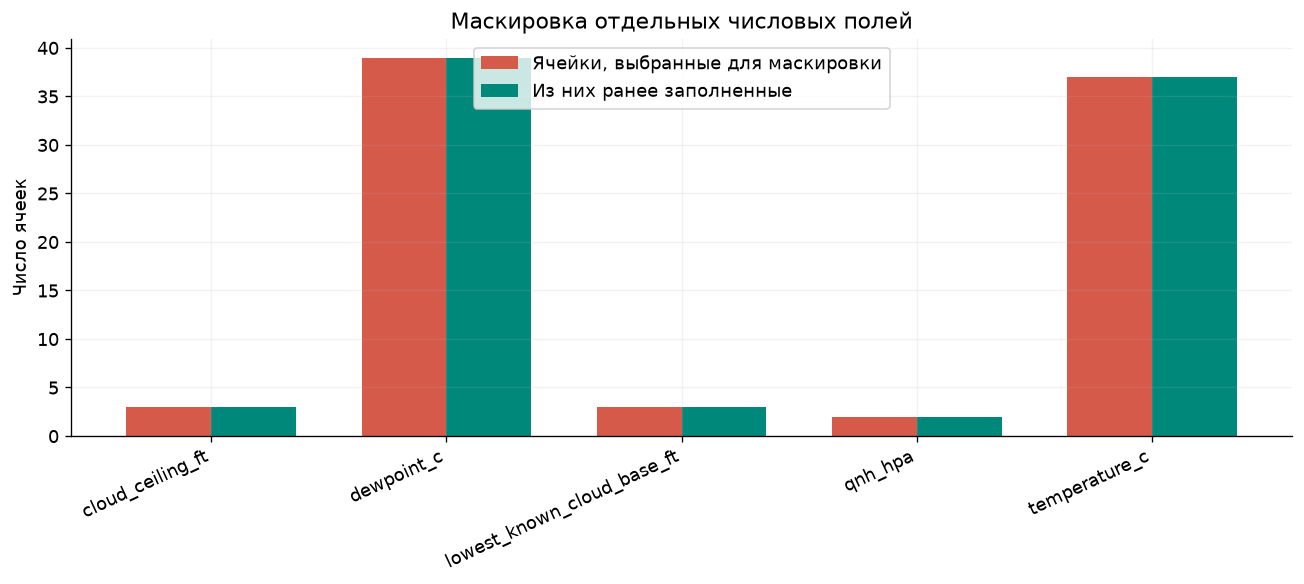

source_row,airport,GoA,metar_id,status,numeric_quality_reasons,original_value,field,model_value,original_value_present
1834005,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834030,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834044,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834063,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834053,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834072,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834081,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834092,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834125,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True
1834107,EHAM,False,5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,matched,temperature_pair_inconsistent,10.0,temperature_c,NaN,True


In [3]:
journal=pd.read_csv(R/'18_numeric_mask_journal.csv')
coverage=pd.read_csv(R/'18_numeric_mask_coverage.csv')
fields=pd.read_csv(R/'18_numeric_mask_fields.csv')
assert coverage.rows.sum()==application['rows']==6331485
assert coverage.loc[coverage.GoA.eq(True),'rows'].sum()==application['go_arounds']==18349
assert not journal.duplicated(['source_row','field']).any()
assert journal.model_value.isna().all()
assert journal.loc[journal.status.eq('matched')].source_row.nunique()==44
display(coverage.groupby('GoA')[['rows','flagged_rows','flagged_rows_matched_60min']].sum())
readable_table(fields)
fig,ax=plt.subplots(figsize=(11,5))
x=np.arange(len(fields))
ax.bar(x-.18,fields.masked_cells,.36,color=CORAL,label='Ячейки, выбранные для маскировки')
ax.bar(x+.18,fields.previously_present,.36,color=GREEN,label='Из них ранее заполненные')
ax.set_xticks(x,fields.field,rotation=25,ha='right')
ax.set(ylabel='Число ячеек',title='Маскировка отдельных числовых полей')
ax.legend()
save('28_numeric_mask_fields')
readable_table(journal)


## 3. Проверки сохраненных файлов

Скрипт применения повторно прочитал каждую сохраненную часть: все исходные
поля совпали, выбранные модельные поля стали пропусками, остальные модельные
значения совпали с исходными. Идентификаторы строк покрывают вход ровно один
раз, обе метки сохранены. Ниже повторно проверяются SHA-256 всех 93 исходных
файлов и всех 93 файлов копии относительно журнала применения.


In [4]:
assert len(application['files'])==93
for item in application['files']:
    assert sha(DATA/'full/results'/item['name'])==item['source_sha256']
    assert sha(DATA/'numeric_quality_v1'/item['name'])==item['output_sha256']
assert sha(BASE/'scripts/apply_numeric_quality.py')==application['implementation_sha256']
assert sha(R/'17_numeric_quality_preview.csv')==application['registry_sha256']
display(pd.DataFrame([{'Проверено исходных файлов':93,'Проверено файлов копии':93,
    'Удалено строк':0,'Исходные числовые значения сохранены':True}]))
sample=journal.loc[journal.status.eq('matched')].drop_duplicates('source_row').head(6)
parts=[]
for item in application['files']:
    if item['flagged_rows']==0:continue
    frame=pd.read_parquet(DATA/'numeric_quality_v1'/item['name'])
    part=frame.loc[frame.source_row.isin(sample.source_row)]
    if not part.empty:parts.append(part)
examples=pd.concat(parts,ignore_index=True)
readable_table(examples[['source_row','airport','metar','numeric_quality_reasons',
    'temperature_c','temperature_c_model','dewpoint_c','dewpoint_c_model',
    'qnh_hpa','qnh_hpa_model','cloud_ceiling_ft','cloud_ceiling_ft_model']])


,Проверено исходных файлов,Проверено файлов копии,Удалено строк,Исходные числовые значения сохранены
0,93,93,0,True


source_row,airport,metar,numeric_quality_reasons,temperature_c,temperature_c_model,dewpoint_c,dewpoint_c_model,qnh_hpa,qnh_hpa_model,cloud_ceiling_ft,cloud_ceiling_ft_model
1834005,EHAM,EHAM 311325Z 09009KT 050V120 CAVOK 10/12 Q1021 NOSIG,temperature_pair_inconsistent,10.0,NaN,12.0,NaN,1021.0,1021.0,NaN,NaN
1834030,EHAM,EHAM 311325Z 09009KT 050V120 CAVOK 10/12 Q1021 NOSIG,temperature_pair_inconsistent,10.0,NaN,12.0,NaN,1021.0,1021.0,NaN,NaN
1834044,EHAM,EHAM 311325Z 09009KT 050V120 CAVOK 10/12 Q1021 NOSIG,temperature_pair_inconsistent,10.0,NaN,12.0,NaN,1021.0,1021.0,NaN,NaN
1834063,EHAM,EHAM 311325Z 09009KT 050V120 CAVOK 10/12 Q1021 NOSIG,temperature_pair_inconsistent,10.0,NaN,12.0,NaN,1021.0,1021.0,NaN,NaN
1834053,EHAM,EHAM 311325Z 09009KT 050V120 CAVOK 10/12 Q1021 NOSIG,temperature_pair_inconsistent,10.0,NaN,12.0,NaN,1021.0,1021.0,NaN,NaN
1834072,EHAM,EHAM 311325Z 09009KT 050V120 CAVOK 10/12 Q1021 NOSIG,temperature_pair_inconsistent,10.0,NaN,12.0,NaN,1021.0,1021.0,NaN,NaN


## 4. Ограничения и продолжение

Причины пропуска по числовому качеству сохранены отдельно. Отсутствие флага
не означает физическую достоверность. Для температурных пар замаскированы обе
компоненты, поскольку источник ошибочного компонента не установлен.

Не выполнены импутация, расчет влажности и других зависимых признаков,
обучение, замена METAR более старым сообщением или восстановление по будущим
наблюдениям. Копия содержит все статусы сопоставления; доступность и давность
не обходятся числовой проверкой. Регистр четырех экстремумов — результат
ретроспективного аудита, а не правило обнаружения ошибок на новых данных.

Следующий этап — отдельный аудит остаточных форматов декодирования и затем
согласование основного сценария доступности погодных признаков на C40.
[Принятый протокол](../reports/17_numeric_quality_protocol.md).
